# 04 · Entropy, Varentropy, and the Confident-but-Wrong Gap

*Evaluation / diagnostics workstream.*

This notebook is the coding version of the "entropy trace-walk" exercise some of you may recognize from
your interview. `PROPOSAL.md`'s **RQ2** asks about the mechanistic signature of *confident-but-wrong*
reasoning: the failure mode where a model asserts a false step fluently, and the output distribution is
sharp, not flat. Token-level entropy and varentropy (`PROPOSAL.md` § 4.4, citing Li et al., 2026) are the
standard surface signals for "the model is uncertain here." This notebook shows concretely why they
can't, by construction, catch the confident-but-wrong case.


In [1]:
import torch
from transformer_lens import HookedTransformer

torch.manual_seed(0)
model = HookedTransformer.from_pretrained("gpt2", device="cpu")


/tmp/ipykernel_4991/942483794.py:5: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gpt2", device="cpu")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded pretrained model gpt2 into HookedTransformer


## Grounding entropy in a real model

Entropy of a next-token distribution measures how spread out it is: near zero when the model is highly
confident in one token, high when many tokens are plausible. Let's see both cases on GPT-2.


In [2]:
def entropy(probs):
    probs = probs.clamp_min(1e-12)
    return -(probs * probs.log()).sum().item()

def varentropy(probs):
    probs = probs.clamp_min(1e-12)
    surprisal = -probs.log()
    mean_surprisal = (probs * surprisal).sum()
    return (probs * (surprisal - mean_surprisal) ** 2).sum().item()

for prompt in ["Water is made of hydrogen and", "I think the best approach here is to"]:
    logits = model(model.to_tokens(prompt))
    probs = torch.softmax(logits[0, -1, :], dim=-1)
    print(f"{prompt!r:42s}  entropy={entropy(probs):.3f}  varentropy={varentropy(probs):.3f}")


'Water is made of hydrogen and'             entropy=2.612  varentropy=7.613


'I think the best approach here is to'      entropy=5.471  varentropy=4.611


The confident, near-certain completion ("...and [oxygen]") should come out with much lower entropy than
the open-ended one; that's entropy working exactly as intended, as a measure of surface uncertainty.


## The gap: two "confident" steps, one of them wrong

GPT-2 small isn't a reasoning model, so we can't reliably make it produce a real multi-step
confidently-wrong chain of thought on demand. Instead, we construct the situation directly: two toy
"reasoning steps" for the prompt "2 + 2 = ", each as a probability distribution over a small vocabulary,
both **equally sharp** (equally confident). Step A confidently predicts "4" (correct). Step B confidently
predicts "5" instead (simply wrong, 2 + 2 != 5), with the exact same sharpness as step A: the model isn't
hedging, it's just as sure about the wrong answer as it was about the right one.


In [3]:
import matplotlib.pyplot as plt

toy_vocab = ["4", "5", "22", "Paris", "Berlin"]

# Step A: "2 + 2 = ", confident AND correct: puts 95% of its mass on "4"
step_a = torch.tensor([0.95, 0.02, 0.01, 0.01, 0.01])

# Step B: "2 + 2 = " but the model has (hypothetically) locked onto a wrong premise upstream and
# now confidently asserts a wrong continuation: puts 95% of its mass on "5" instead, same sharpness
# as step A, just a different (wrong) token
step_b = torch.tensor([0.02, 0.95, 0.01, 0.01, 0.01])

# Step C, for contrast: a genuinely uncertain branching point (e.g. "the answer is either... ")
step_c = torch.tensor([0.30, 0.30, 0.30, 0.05, 0.05])

# which token each distribution is confident about, and whether it's actually correct for "2 + 2 = "
correct_answer = "4"
steps = {"A: confident & correct": step_a, "B: confident & WRONG": step_b, "C: genuinely uncertain": step_c}

print(f"{'step':28s}{'predicts':>10s}{'entropy':>10s}{'varentropy':>12s}")
for name, dist in steps.items():
    top_token = toy_vocab[dist.argmax().item()]
    flag = "" if top_token == correct_answer else "  <- wrong! 2 + 2 != " + top_token
    print(f"{name:28s}{top_token:>10s}{entropy(dist):>10.3f}{varentropy(dist):>12.3f}{flag}")


step                          predicts   entropy  varentropy
A: confident & correct               4     0.265       0.875
B: confident & WRONG                 5     0.265       0.875  <- wrong! 2 + 2 != 5
C: genuinely uncertain               4     1.383       0.289


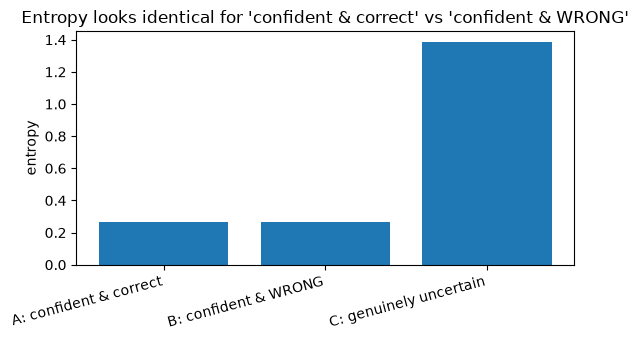

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
names = list(steps.keys())
entropies = [entropy(steps[n]) for n in names]
ax.bar(names, entropies)
ax.set_ylabel("entropy")
ax.set_title("Entropy looks identical for 'confident & correct' vs 'confident & WRONG'")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


## What you should take away

- Step A and step B have (by construction) **the same entropy and the same varentropy**, because both
  are the model being equally confident. Entropy has no way to distinguish "confident because correct"
  from "confident because it locked onto a wrong premise." This is not a limitation of this toy example;
  it is the actual, structural blind spot `PROPOSAL.md` § 1 and RQ2 describe: *"when a model is
  confidently wrong, its output distribution is sharp, not flat."*
- Step C shows what entropy *is* good at: flagging genuine branching/uncertainty (Li et al., 2026's
  entropy-gated branching, `PROPOSAL.md` § 2.2), which is a different, real, and useful signal, just not
  the one this project is chasing.
- This is precisely why the project looks *inside* the model (SAE features on the reasoning trajectory)
  instead of only at the output distribution: the internal computation that produced step B might carry
  a trace (e.g., a premise-commitment feature firing when it shouldn't) that entropy simply can't see
  from the outside.
